# Smart Supply — AI Fundamentals Final Project

**Name:** Sagydat Rahat
**Group:** 5 поток
**Course:** AI Fundamentals — Final Project

**Problem.** A small chain of 10 shops runs out of a popular product or over-orders it. Every morning the manager must decide **how much to order, from which supplier, and by which road**.

**Solution.** Three AI topics from the course work as one pipeline:

| # | AI topic | Algorithm | Real data | Output passed on |
|---|---|---|---|---|
| 1 | Supervised learning | Linear Regression | Kaggle *Store Item Demand* (1 826 days) | demand for the delivery days |
| 1 | Supervised learning | Logistic Regression | Kaggle *DataCo Supply Chain* (172 765 orders) | P(late) per supplier |
| 2 | Probabilistic reasoning | Naive Bayes | 160 labelled supplier messages (own) | problem type in today's message |
| 3 | Heuristic search | A* | 16 Kazakhstan cities, 18 roads | route and km per supplier |

Every section prints **INPUT → STEPS → OUTPUT → WHY**.

In [1]:
# Setup: works in Google Colab (clones the repo) and locally (run from the repo or notebooks/ folder)
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
if not os.path.exists("src/smart_supply"):
    os.system("git clone -q https://github.com/sagydatrahat-gif/smart-supply.git")
    os.chdir("smart-supply")
sys.path.insert(0, "src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from smart_supply import demand, delay_risk, messages, routing, captain
print("Ready. Data files:", sorted(os.listdir("data/processed")))

Ready. Data files: ['deliveries.csv', 'kz_cities.csv', 'kz_roads.csv', 'messages.csv', 'sales_item1_chain.csv']


## 1. Linear Regression — demand forecast (AI topic 1: supervised learning, regression)

**Idea.** Find weights so that `y = b + w_t·t + Σ w_weekday·weekday + Σ w_month·month` has the smallest mean squared error on past days.
**Split.** Train 2013–2016, test 2017 (no shuffling: in time series the future must stay in the test set).
**Baselines.** "Same weekday last week" and "always the average". The model is useful only if it beats them.

In [2]:
sales = demand.load_sales()
dem = demand.run(sales)


 [1] Linear Regression — how much will the shops sell?
INPUT  : 1826 days of real sales (Kaggle), item 1 in 10 stores, 2013-01-01 .. 2017-12-31
         train = 1461 days (2013-2016), test = 365 days (2017)
         features: trend t, weekday (6 dummies), month (11 dummies) = 18 numbers per day
STEPS  : 1) least squares finds w and b that minimise MSE = mean((y - y_hat)^2)
            b (intercept) =    71.35
            w_t          =    0.048
            w_Tue        =   27.757
            w_Wed        =   28.486
            w_Thu        =   41.318
            w_Fri        =   56.556
            w_Sat        =   70.119
            w_Sun        =   83.829
            w_Feb        =   15.877
            w_Mar        =   46.110
            w_Apr        =   79.470
            w_May        =   90.162
            w_Jun        =  112.547
            w_Jul        =  123.445
            w_Aug        =   87.333
            w_Sep        =   69.513
            w_Oct        =   52.020
          

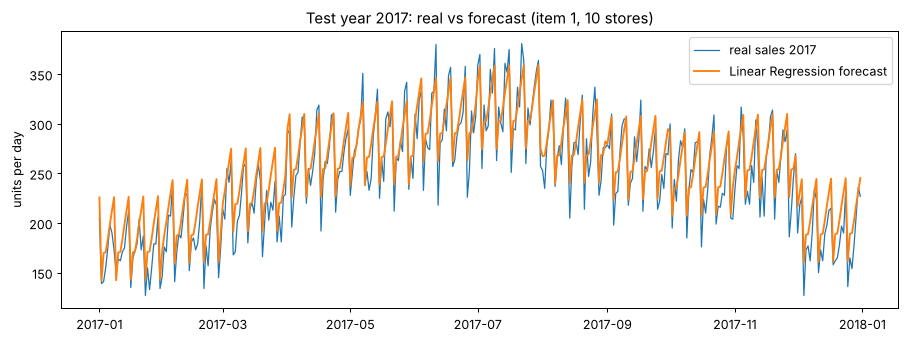

In [3]:
test = dem["test"]
plt.figure(figsize=(12, 4))
plt.plot(test["date"], test["sales"], label="real sales 2017", linewidth=1)
plt.plot(test["date"], dem["pred"], label="Linear Regression forecast", linewidth=1.5)
plt.title("Test year 2017: real vs forecast (item 1, 10 stores)")
plt.ylabel("units per day"); plt.legend(); plt.show()

## 2. Logistic Regression — late-delivery risk (AI topic 1: supervised learning, classification)

**Idea.** `z = b + Σ w·x`, then `P(late) = 1 / (1 + e^(−z))`; weights are learned by minimising log loss.
**Leakage removed.** *Days for shipping (real)* and *Delivery Status* are known only after delivery, so they are not used.
**Privacy.** Customer names, e-mails, passwords and streets are dropped in `prepare_data.py`.

In [4]:
deliveries = delay_risk.load_deliveries()
risk = delay_risk.run(deliveries)


 [2] Logistic Regression — will a supplier deliver late?
INPUT  : 172765 real orders (Kaggle DataCo), late share = 57.3%
         train = 129573, test = 43192 (stratified 75/25 split)
         features known at order time: shipping_mode, payment_type, market, quantity
         removed on purpose: real shipping days, delivery status (leakage); names, e-mails (privacy)
STEPS  : 1) one-hot encode categories, standardise numbers, learn weights by minimising log loss
         2) supplier A (Shymkent): {'shipping_mode': 'Second Class', 'payment_type': 'DEBIT', 'market': 'Pacific Asia', 'quantity': 5}
            z = b = +1.296
                -0.503 * +1.000 = -0.503   (shipping_mode_Second Class)
                +0.331 * +1.000 = +0.331   (payment_type_DEBIT)
                +0.264 * +1.000 = +0.264   (market_Pacific Asia)
                -0.004 * +1.977 = -0.008   (quantity)
            z = +1.380
         3) P(late) = 1 / (1 + e^(-z)) = 1 / (1 + e^(-1.380)) = 0.799
OUTPUT : test results:

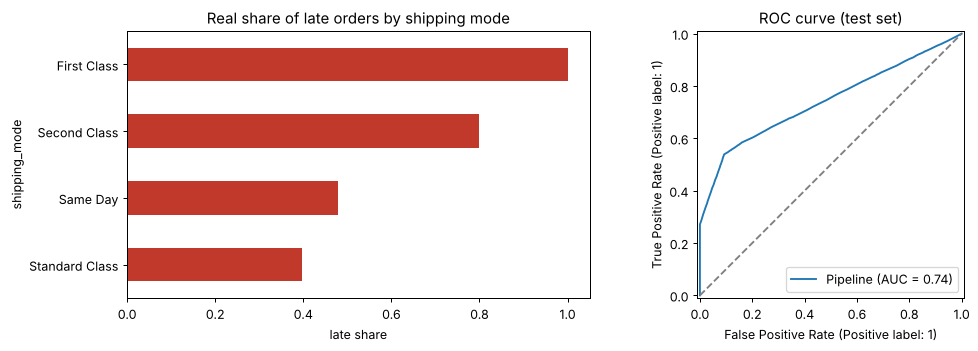

In [5]:
from sklearn.metrics import RocCurveDisplay
from sklearn.model_selection import train_test_split
X_tr, X_te, y_tr, y_te = train_test_split(deliveries[delay_risk.FEATURES], deliveries["late"],
                                          test_size=0.25, random_state=1103, stratify=deliveries["late"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
deliveries.groupby("shipping_mode")["late"].mean().sort_values().plot.barh(ax=ax[0], color="#c0392b")
ax[0].set_title("Real share of late orders by shipping mode"); ax[0].set_xlabel("late share")
RocCurveDisplay.from_estimator(risk["model"], X_te, y_te, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "--", color="grey"); ax[1].set_title("ROC curve (test set)")
plt.tight_layout(); plt.show()

## 3. Naive Bayes — reading supplier messages (AI topic 2: probabilistic reasoning)

**Idea.** `P(C | words) ∝ P(C) · Π P(word | C)` with Laplace smoothing, so an unseen word never makes a probability zero.
**Data.** No public dataset of supplier messages exists, so 160 messages were written and labelled by hand (40 per class). This is a limitation.

In [6]:
msgs = messages.load_messages()
nb = messages.run(msgs)


 [3] Naive Bayes — what does the supplier's message mean?
INPUT  : 160 labelled supplier messages (own dataset, 40 per class): Delay, Damage, Docs, On track
         train = 120, test = 40 (stratified 75/25 split)
         new message: "Cargo held at customs, documents not processed yet"
STEPS  : 1) split text into words, drop stop-words, count words per class
         2) P(word|C) = (count of word in C + 1) / (all words in C + vocabulary size)   <- Laplace
         3) known words in the message: ['cargo', 'held', 'customs', 'documents', 'processed']
            Damage   : P(C)=0.250 * 0.0045 * 0.0022 * 0.0022 * 0.0022 * 0.0022 = 2.833e-14
            Delay    : P(C)=0.250 * 0.0087 * 0.0087 * 0.0087 * 0.0022 * 0.0022 = 7.602e-13
            Docs     : P(C)=0.250 * 0.0023 * 0.0023 * 0.0070 * 0.0188 * 0.0047 = 8.553e-13
            On track : P(C)=0.250 * 0.0096 * 0.0024 * 0.0024 * 0.0048 * 0.0024 = 1.567e-13
         4) divide each score by their sum: Damage 1.6%, Delay 42.2%, Docs 47.

In [7]:
# Try any message yourself
for text in ["Two boxes arrived crushed and milk is leaking",
             "Please resend the signed invoice",
             "Truck left on schedule this morning"]:
    label, proba = messages.classify(nb["model"], text)
    print(f"{label:<9} {max(proba.values()):.0%}  <- {text}")

Damage    100%  <- Two boxes arrived crushed and milk is leaking
Docs      98%  <- Please resend the signed invoice
On track  76%  <- Truck left on schedule this morning


## 4. A* — delivery route (AI topic 3: heuristic search)

**Idea.** Expand the city with the smallest `f(n) = g(n) + h(n)`: km already driven plus straight-line km to the shop.
**Why it is optimal.** Every road is at least as long as the straight line, so `h` never overestimates (admissible heuristic).
**Check.** Dijkstra (A* with `h = 0`) must give the same km, while A* expands fewer cities.

In [8]:
graph, coords = routing.load_map()
routes = routing.run(graph, coords)


 [4] A* search — which road should the truck take?
INPUT  : map of 16 Kazakhstan cities, 18 roads (km = straight line * 1.25)
         goal: our shop in Kyzylorda; starts: A (Shymkent) -> Shymkent, B (Almaty) -> Almaty, C (Kostanay) -> Kostanay
STEPS  : f(n) = g(n) + h(n); g = km driven so far, h = straight-line km left to Kyzylorda
         always expand the open city with the smallest f; stop when the goal is expanded
         expansion order for C (Kostanay):
           step  city       g     h    f   
           ----  ---------  ----  ---  ----
           1     Kostanay   0     940  940 
           2     Astana     724   831  1555
           3     Aktobe     689   868  1556
           4     Aralsk     1326  366  1692
           5     Karaganda  963   794  1757
           6     Kyzylorda  1784  0    1784
OUTPUT : supplier      A* route                                               km    A* expanded  Dijkstra km  Dijkstra expanded
         ------------  -----------------------------

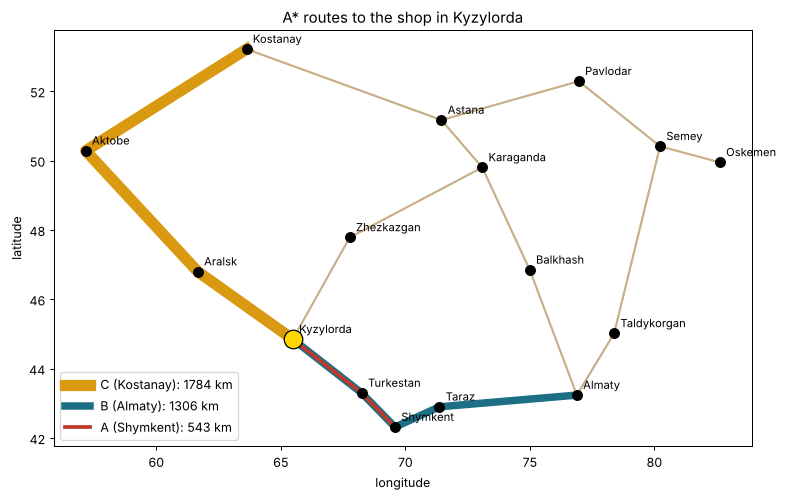

In [9]:
plt.figure(figsize=(10, 6))
for a, nbrs in graph.items():
    for b in nbrs:
        plt.plot([coords[a][1], coords[b][1]], [coords[a][0], coords[b][0]], color="#c9b28a", zorder=1)
colors = {"A (Shymkent)": "#c0392b", "B (Almaty)": "#1d6f86", "C (Kostanay)": "#d99a12"}
for width, (name, r) in zip([9, 6, 3], sorted(routes.items(), key=lambda kv: -kv[1]["km"])):
    xs = [coords[c][1] for c in r["path"]]; ys = [coords[c][0] for c in r["path"]]
    plt.plot(xs, ys, linewidth=width, color=colors[name], label=f"{name}: {r['km']:.0f} km", zorder=2)  # longest = widest
for city, (lat, lon) in coords.items():
    plt.scatter(lon, lat, s=60 if city != routing.SHOP else 220, color="black" if city != routing.SHOP else "gold",
                edgecolor="black", zorder=3)
    plt.annotate(city, (lon, lat), xytext=(5, 5), textcoords="offset points", fontsize=9)
plt.title("A* routes to the shop in Kyzylorda"); plt.xlabel("longitude"); plt.ylabel("latitude")
plt.legend(); plt.show()

## 5. The Captain — one decision from all three topics

Linear Regression gives *how much*, Logistic Regression + Naive Bayes give *how risky*, A* gives *how far*.
`cost = km · 220 ₸ + risk · 3 days · daily demand · 650 ₸`; the cheapest supplier is recommended, and a human manager confirms it.

In [10]:
today = {
    "A (Shymkent)": "Our truck is stuck at the border and will be late",
    "B (Almaty)": "Truck loaded and left on time",
    "C (Kostanay)": "Invoice is missing, please send the documents",
}
rows, best = captain.run(dem, risk, nb, routes, today, stock=300)


 [5] The Captain — one decision from all AI results
INPUT  : stock on hand = 300 units; today's messages:
           A (Shymkent): "Our truck is stuck at the border and will be late"
           B (Almaty): "Truck loaded and left on time"
           C (Kostanay): "Invoice is missing, please send the documents"
STEPS  : lead time = ceil(km / 600) + 1, order = forecast(lead) + 1.65*RMSE*sqrt(lead) - stock
         risk = P(late) + message bonus {'Delay': 0.2, 'Damage': 0.15, 'Docs': 0.1, 'On track': 0.0}
         cost = km * 220 KZT + risk * 3 days * daily demand * 650 KZT
         supplier      km    days  demand+safety  order  P(late)  message   risk  transport  delay cost  TOTAL KZT
         ------------  ----  ----  -------------  -----  -------  --------  ----  ---------  ----------  ---------
         A (Shymkent)  543   2     326+45         72     80%      Delay     99%   119,548    314,860     434,408  
         B (Almaty)    1306  4     696+63         460    40%      On track  4

In [11]:
# What if Shymkent's message is good news? The decision changes.
today["A (Shymkent)"] = "Truck loaded and left on time"
rows, best = captain.run(dem, risk, nb, routes, today, stock=300)


 [5] The Captain — one decision from all AI results
INPUT  : stock on hand = 300 units; today's messages:
           A (Shymkent): "Truck loaded and left on time"
           B (Almaty): "Truck loaded and left on time"
           C (Kostanay): "Invoice is missing, please send the documents"
STEPS  : lead time = ceil(km / 600) + 1, order = forecast(lead) + 1.65*RMSE*sqrt(lead) - stock
         risk = P(late) + message bonus {'Delay': 0.2, 'Damage': 0.15, 'Docs': 0.1, 'On track': 0.0}
         cost = km * 220 KZT + risk * 3 days * daily demand * 650 KZT
         supplier      km    days  demand+safety  order  P(late)  message   risk  transport  delay cost  TOTAL KZT
         ------------  ----  ----  -------------  -----  -------  --------  ----  ---------  ----------  ---------
         A (Shymkent)  543   2     326+45         72     80%      On track  80%   119,548    254,119     373,667  
         B (Almaty)    1306  4     696+63         460    40%      On track  40%   287,210    135,

## 6. Results summary
All metrics are on data the models did not see in training. Every model beats its simple baseline.

In [12]:
summary = pd.DataFrame([
    ["Linear Regression", "RMSE (units)", dem["metrics"]["RMSE"], dem["baseline_week"]["RMSE"]],
    ["Linear Regression", "MAE (units)", dem["metrics"]["MAE"], dem["baseline_week"]["MAE"]],
    ["Linear Regression", "R²", dem["metrics"]["R2"], dem["baseline_week"]["R2"]],
    ["Logistic Regression", "Accuracy", risk["metrics"]["accuracy"], risk["baseline"]["accuracy"]],
    ["Logistic Regression", "Precision", risk["metrics"]["precision"], risk["baseline"]["precision"]],
    ["Logistic Regression", "ROC-AUC", risk["metrics"]["roc_auc"], 0.5],
    ["Naive Bayes", "Accuracy", nb["accuracy"], nb["baseline_accuracy"]],
    ["Naive Bayes", "Macro-F1", nb["macro_f1"], None],
    ["A* (Kostanay)", "km (A* vs Dijkstra)", routes["C (Kostanay)"]["km"], routes["C (Kostanay)"]["dijkstra_km"]],
    ["A* (Kostanay)", "cities expanded", routes["C (Kostanay)"]["expanded"], routes["C (Kostanay)"]["dijkstra_expanded"]],
], columns=["algorithm", "metric", "model", "baseline / Dijkstra"]).round(3)
summary

,algorithm,metric,model,baseline / Dijkstra
0,Linear Regression,RMSE (units),19.218,25.689
1,Linear Regression,MAE (units),15.804,19.781
2,Linear Regression,R²,0.882,0.789
3,Logistic Regression,Accuracy,0.696,0.573
4,Logistic Regression,Precision,0.886,0.573
5,Logistic Regression,ROC-AUC,0.742,0.500
6,Naive Bayes,Accuracy,0.800,0.250
7,Naive Bayes,Macro-F1,0.798,NaN
8,A* (Kostanay),km (A* vs Dijkstra),1783.900,1783.900
9,A* (Kostanay),cities expanded,6.000,10.000


## 7. Limitations and next steps
- Sales data is one Kaggle product, not a real Kazakh shop; connect real cash-register data next.
- DataCo is a global e-commerce dataset; supplier profiles are mapped onto its shipping modes.
- Supplier messages are self-written (160); more real messages and Kazakh/Russian support are needed.
- Road km = straight line × 1.25; a real OpenStreetMap road graph would give exact distances.
- Cost constants (220 ₸/km, 650 ₸ margin) are assumptions and should come from the business.